# 03 — Comparar o comparável

**A pergunta:** em mercados com menos companhias, a tarifa por quilômetro
é mais alta, **comparando distâncias parecidas**?

O notebook 02 comparou os mercados sem controle nenhum e não chegou a uma
resposta: os mercados com um concorrente só são mais longos, e a
distância deixa o quilômetro mais barato e a passagem mais cara. Aqui a
comparação é refeita entre mercados de distância parecida, primeiro
dentro de faixas e depois numa regressão.

Faz parte da [etapa 7](../README.md#etapas) do projeto. Os dados vêm de
`dados/marts/mercado_mes.parquet` (um registro por mercado, mês e grupo) e
de `dados/marts/dim_mercado.parquet` (a distância de cada mercado), os dois
montados pelo `construir.py` a partir da coleta de 13/10/2026. As
definições são as do notebook 02: concorrente é o grupo com pelo menos 5%
dos passageiros de voo regular do mercado no mês, e a tarifa por km é a
receita dividida pelos assentos-km, as duas somadas.

## 1. As faixas de distância, declaradas antes de olhar

Cada mercado entra numa de quatro faixas, pela distância em linha reta
entre as duas cidades:

| Faixa | Distância |
|---|---|
| curta | até 500 km |
| média | de 500 a 1.000 km |
| longa | de 1.000 a 2.000 km |
| muito longa | acima de 2.000 km |

As fronteiras são números redondos, escolhidas antes de qualquer conta por
faixa, e não mudam depois de ver o resultado: fronteira escolhida olhando
a tarifa acharia a diferença que se quisesse. Dentro de cada faixa, a
comparação é a do notebook 02, ano a ano, pelo ano da venda.

In [1]:
import pandas as pd

URL = "https://raw.githubusercontent.com/ivadivad/voos-em-numeros/coleta-2026-10-13/dados/marts/mercado_mes.parquet"
DIM_MERCADO = "https://raw.githubusercontent.com/ivadivad/voos-em-numeros/coleta-2026-10-13/dados/marts/dim_mercado.parquet"
mart = pd.read_parquet(URL)
distancia = pd.read_parquet(DIM_MERCADO).set_index("mercado")["distancia_km"].astype(float)

# um registro por mercado e mes: as somas dos grupos e a concentracao do mercado
mercados = mart.groupby(["mes", "mercado"]).agg(
    concorrentes=("concorrentes", "first"), passageiros=("passageiros_pagos", "sum"),
    receita=("receita", "sum"), assentos=("assentos_vendidos", "sum")).reset_index()
mercados["mes"] = pd.to_datetime(mercados["mes"])
mercados["ano"] = mercados["mes"].dt.year
mercados["distancia_km"] = mercados["mercado"].map(distancia)
mercados["assentos_km"] = mercados["assentos"] * mercados["distancia_km"]
CLASSES = ["1", "2", "3 ou mais"]
mercados["classe"] = mercados["concorrentes"].clip(upper=3).map(dict(zip([1, 2, 3], CLASSES)))
FAIXAS = ["até 500 km", "500 a 1.000 km", "1.000 a 2.000 km", "acima de 2.000 km"]
mercados["faixa"] = pd.cut(mercados["distancia_km"], [0, 500, 1000, 2000, float("inf")], labels=FAIXAS)

com_tarifa = mercados[(mercados["assentos"] > 0) & mercados["distancia_km"].notna()].copy()
print(f"{len(mercados)} mercado-meses; {len(com_tarifa)} com tarifa vendida e distância, "
      f"{mercados['assentos'].eq(0).sum()} sem tarifa e {mercados['distancia_km'].isna().sum()} sem distância")

30886 mercado-meses; 29554 com tarifa vendida e distância, 1329 sem tarifa e 3 sem distância


A unidade daqui em diante é o mercado no mês: as somas de todos os grupos
e o número de concorrentes do mercado. Entram os 29.554 mercado-meses com
tarifa vendida e distância conhecida. Ficam de fora 1.329 sem nenhuma
tarifa vendida no mês e 3 sem distância.

## 2. A tarifa por km dentro de cada faixa

Primeiro a composição: quantos mercados de cada tipo há em cada faixa, e
se a faixa aproxima a distância dos mercados de um concorrente da dos
mercados de três ou mais.

In [2]:
ano = com_tarifa[com_tarifa["ano"] == 2025]
s = ano.groupby(["faixa", "classe"], observed=True).agg(
    mercado_meses=("mercado", "size"), assentos=("assentos", "sum"), assentos_km=("assentos_km", "sum"))
s["% dos assentos da faixa"] = s["assentos"] / s.groupby(level="faixa", observed=True)["assentos"].transform("sum") * 100
s["distância média (km)"] = s["assentos_km"] / s["assentos"]
print("2025, por faixa e número de concorrentes")
print(s[["mercado_meses", "% dos assentos da faixa", "distância média (km)"]].round(0).to_string())

2025, por faixa e número de concorrentes
                             mercado_meses  % dos assentos da faixa  distância média (km)
faixa             classe                                                                 
até 500 km        1                   1022                     12.0                 385.0
                  2                    117                     16.0                 391.0
                  3 ou mais             99                     73.0                 371.0
500 a 1.000 km    1                    639                     12.0                 780.0
                  2                    209                     22.0                 763.0
                  3 ou mais            191                     66.0                 723.0
1.000 a 2.000 km  1                    715                     21.0                1519.0
                  2                    324                     31.0                1390.0
                  3 ou mais            159                 

**Dentro das faixas, a distância média quase se iguala.** Em 2025, até
500 km, os mercados de um concorrente têm 385 km em média e os de três ou
mais, 371; de 1.000 a 2.000 km, 1.519 e 1.518. A distância que sobra é
maior de 500 a 1.000 km (780 e 723) e acima de 2.000 km (2.459 e 2.270),
sempre com os de um concorrente mais longos. Em toda faixa, eles são os
mais numerosos e levam de 12% a 21% dos assentos vendidos.

In [3]:
def tarifa_km(registros, por):
    """Tarifa por km da razao entre as somas, em cada combinacao de `por`."""
    s = registros.groupby(por, observed=True)[["receita", "assentos_km"]].sum()
    return s["receita"] / s["assentos_km"]


print("tarifa por km em 2025, todas as classes juntas (R$)")
print(tarifa_km(com_tarifa[com_tarifa["ano"] == 2025], "faixa").round(3).to_string(), "\n")

por_faixa = tarifa_km(com_tarifa, ["faixa", "ano", "classe"]).unstack("classe")
print("tarifa por km em 2025 (R$)")
print(por_faixa.xs(2025, level="ano").round(3).to_string(), "\n")

completos = por_faixa.dropna()
resumo = pd.DataFrame({
    "anos com as três classes": completos.groupby(level="faixa", observed=True).size(),
    "1 acima de 3 ou mais": (completos["1"] > completos["3 ou mais"]).groupby(level="faixa", observed=True).sum(),
    "2 entre 1 e 3 ou mais": ((completos["2"] < completos["1"]) & (completos["2"] > completos["3 ou mais"]))
                             .groupby(level="faixa", observed=True).sum(),
    "1 sobre 3 ou mais, mediana dos anos (%)": ((completos["1"] / completos["3 ou mais"] - 1) * 100)
                                               .groupby(level="faixa", observed=True).median().round(1),
})
print("de 2019 a 2026, faixa a faixa")
print(resumo.to_string())

tarifa por km em 2025, todas as classes juntas (R$)
faixa
até 500 km           1.201
500 a 1.000 km       0.646
1.000 a 2.000 km     0.462
acima de 2.000 km    0.355 

tarifa por km em 2025 (R$)
classe                 1      2  3 ou mais
faixa                                     
até 500 km         1.653  0.980      1.176
500 a 1.000 km     0.817  0.670      0.603
1.000 a 2.000 km   0.474  0.511      0.429
acima de 2.000 km  0.354  0.376      0.351 

de 2019 a 2026, faixa a faixa
                   anos com as três classes  1 acima de 3 ou mais  2 entre 1 e 3 ou mais  1 sobre 3 ou mais, mediana dos anos (%)
faixa                                                                                                                            
até 500 km                                8                     8                      2                                     25.5
500 a 1.000 km                            8                     8                      7                                     

**Comparando distâncias parecidas, um concorrente só cobra mais por km em
todas as faixas até 2.000 km, todos os anos.** De 2019 a 2026, a tarifa
por km dos mercados de um concorrente fica acima da dos de três ou mais
em 8 dos 8 anos até 500 km, de 500 a 1.000 km e de 1.000 a 2.000 km, e a
diferença mediana entre os anos é de 25,5%, 23,2% e 10,5%. Acima de
2.000 km, ela some: 5 dos 8 anos, mediana de 0,7%. Em 2025, até 500 km, o
km sai R\$ 1,653 onde há um concorrente e R\$ 1,176 onde há três ou mais.

O quilômetro fica mais barato a cada faixa (em 2025, de R\$ 1,201 até
500 km a R\$ 0,355 acima de 2.000 km, todas as classes juntas), e os
mercados de um concorrente são um pouco mais longos dentro da faixa. A
distância que sobra joga contra o resultado: sem ela, a diferença seria
maior, não menor.

Os mercados de dois concorrentes seguem sem lugar fixo: ficam entre os
outros dois em 7 dos 8 anos de 500 a 1.000 km, em 5 de 1.000 a 2.000 km,
em 2 até 500 km e em 1 acima de 2.000 km.

## 3. A regressão

A faixa ainda deixa a distância variar dentro dela, e cada ano foi olhado
à parte. A regressão compara, de uma vez, cada mercado no mês com os de
mesma distância e do mesmo mês:

`log(tarifa por km) ~ log(distância) + concorrentes + mês`

- **Unidade:** o mercado no mês, os mesmos da seção 1.
- **Concorrentes:** 1, 2, ou 3 ou mais, com três ou mais como referência.
- **Mês:** um efeito pra cada mês, que absorve a inflação e a sazonalidade.
- **Erro-padrão agrupado por mercado:** o mesmo mercado aparece em muitos
  meses, e contar cada mês como observação independente inflaria a
  certeza.
- **Duas versões, declaradas antes de rodar:** sem peso, cada mercado no
  mês conta igual; com peso pelos passageiros, o mercado grande conta
  mais. Se a conclusão mudar entre elas, as duas ficam.

O coeficiente de cada classe vira porcentagem: exp(coeficiente) − 1 é
quanto a tarifa por km é maior que nos mercados de três ou mais, na mesma
distância e no mesmo mês.

In [4]:
import numpy as np
import statsmodels.formula.api as smf

dados = com_tarifa.assign(
    log_tarifa_km=np.log(com_tarifa["receita"] / com_tarifa["assentos_km"]),
    log_distancia=np.log(com_tarifa["distancia_km"]),
    mes_texto=com_tarifa["mes"].dt.strftime("%Y-%m"),
)
FORMULA = "log_tarifa_km ~ log_distancia + C(classe, Treatment('3 ou mais')) + C(mes_texto)"
TERMOS = {"C(classe, Treatment('3 ou mais'))[T.1]": "1 concorrente",
          "C(classe, Treatment('3 ou mais'))[T.2]": "2 concorrentes",
          "log_distancia": "log da distância"}


def estimar(registros):
    """As duas versoes declaradas, com erro-padrao agrupado por mercado."""
    agrupamento = {"groups": pd.factorize(registros["mercado"])[0]}
    return {
        "sem peso": smf.ols(FORMULA, data=registros).fit(cov_type="cluster", cov_kwds=agrupamento),
        "com peso": smf.wls(FORMULA, data=registros, weights=registros["passageiros"]).fit(
            cov_type="cluster", cov_kwds=agrupamento),
    }


def tabela(modelos):
    """Coeficiente, erro-padrao, p e, nas classes, a diferenca em % com o intervalo de 95%."""
    linhas = []
    for versao, r in modelos.items():
        for termo, rotulo in TERMOS.items():
            b, ep = r.params[termo], r.bse[termo]
            linha = {"versão": versao, "termo": rotulo, "coeficiente": round(b, 4), "erro-padrão": round(ep, 4),
                     "p": round(r.pvalues[termo], 4)}
            if termo != "log_distancia":
                linha["% sobre 3 ou mais"] = round((np.exp(b) - 1) * 100, 1)
                linha["IC 95% (%)"] = f"{(np.exp(b - 1.96 * ep) - 1) * 100:.1f} a {(np.exp(b + 1.96 * ep) - 1) * 100:.1f}"
            linhas.append(linha)
    return pd.DataFrame(linhas).fillna("").to_string(index=False)


modelos = estimar(dados)
print(f"{int(modelos['sem peso'].nobs)} mercado-meses e {dados['mercado'].nunique()} mercados, "
      f"que são os grupos do erro-padrão\n")
print(tabela(modelos))

29554 mercado-meses e 961 mercados, que são os grupos do erro-padrão

  versão            termo  coeficiente  erro-padrão      p % sobre 3 ou mais  IC 95% (%)
sem peso    1 concorrente       0.3328       0.0208 0.0000              39.5 33.9 a 45.3
sem peso   2 concorrentes       0.1451       0.0234 0.0000              15.6 10.4 a 21.0
sem peso log da distância      -0.7212       0.0160 0.0000                              
com peso    1 concorrente       0.2525       0.0286 0.0000              28.7 21.7 a 36.1
com peso   2 concorrentes       0.0970       0.0273 0.0004              10.2  4.4 a 16.2
com peso log da distância      -0.6755       0.0292 0.0000                              


**Na mesma distância e no mesmo mês, um concorrente só cobra de 28,7% a
39,5% a mais por km que três ou mais.** Sem peso, a diferença é de 39,5%, com
intervalo de 95% de 33,9% a 45,3%; com peso pelos passageiros, de 28,7%,
de 21,7% a 36,1%. Com peso a estimativa cai, ou seja, nos mercados com
mais passageiros a diferença é menor, mas a conclusão não muda: os dois
intervalos ficam longe do zero. São 29.554 mercado-meses de 961 mercados.

Com a distância controlada, os mercados de dois concorrentes ficam, enfim,
no meio: 15,6% a mais sem peso e 10,2% com peso, os dois intervalos acima
de zero. E a distância faz o que as faixas mostraram: a cada 1% a mais de
distância, a tarifa por km cai cerca de 0,7% (coeficiente de −0,7212 sem
peso e −0,6755 com peso).

A regressão dá uma média de todas as distâncias, e a seção 2 mostra como
ela se distribui: a diferença está nos mercados de até 2.000 km, e some
acima disso.

## 4. O que a regressão não prova

1. **Causalidade reversa.** A regressão mostra associação, não efeito. Uma
   companhia entra onde espera ganhar e sai de onde não espera: um mercado
   pode ter um concorrente só porque não comporta dois, e aí a falta de
   concorrência e a tarifa alta andam juntas sem que uma cause a outra.
   Separar as duas pediria um experimento natural, como comparar o mesmo
   mercado antes e depois da saída de uma companhia.
2. **Mercados pequenos.** No mercado pequeno, a tarifa por km de um mês
   depende de poucas vendas, e a regressão sem peso dá a ele o mesmo peso
   do grande. A conta abaixo mede o tamanho dos mercados de cada classe e
   refaz a regressão sem os mercado-meses com menos de 100 assentos
   vendidos, um corte redondo fixado antes de rodar.
3. **Tarifas fora do registro.** Pelos
   [metadados da ANAC](https://www.gov.br/anac/pt-br/acesso-a-informacao/dados-abertos/areas-de-atuacao/voos-e-operacoes-aereas/tarifas-aereas-domesticas/46-tarifas-aereas-domesticas),
   as tarifas registradas excluem as passagens "adquiridas com descontos
   restritos a grupos específicos, programas de milhagem, entre outras
   condições", e "o número de assentos vendidos registrados corresponde a
   cerca de 50% do movimento de passageiros pagos transportados". Se o
   preço pago fora do registro for diferente onde há menos concorrência, a
   diferença medida aqui não é a do preço pago por todo mundo.

In [5]:
pequeno = dados["assentos"] < 100
print("assentos vendidos por mercado no mês, mediana por classe")
print(dados.groupby("classe")["assentos"].median().to_string(), "\n")
print(f"mercado-meses com menos de 100 assentos: {pequeno.sum()} de {len(dados)} ({pequeno.mean():.1%}); "
      f"entre os de um concorrente, {pequeno[dados['classe'] == '1'].mean():.1%}\n")
print("a regressão sem eles")
print(tabela(estimar(dados[~pequeno])))

assentos vendidos por mercado no mês, mediana por classe
classe
1              711.0
2             4974.0
3 ou mais    17841.0 

mercado-meses com menos de 100 assentos: 4749 de 29554 (16.1%); entre os de um concorrente, 23.6%

a regressão sem eles


  versão            termo  coeficiente  erro-padrão      p % sobre 3 ou mais  IC 95% (%)
sem peso    1 concorrente       0.2692       0.0189 0.0000              30.9 26.1 a 35.8
sem peso   2 concorrentes       0.1374       0.0225 0.0000              14.7  9.8 a 19.9
sem peso log da distância      -0.6900       0.0173 0.0000                              
com peso    1 concorrente       0.2395       0.0284 0.0000              27.1 20.2 a 34.3
com peso   2 concorrentes       0.0960       0.0274 0.0005              10.1  4.3 a 16.1
com peso log da distância      -0.6728       0.0297 0.0000                              


**Os mercados de um concorrente são pequenos, e sem os menores a diferença
diminui, mas fica.** No mês, a mediana é de 711 assentos vendidos onde há
um concorrente, 4.974 onde há dois e 17.841 onde há três ou mais. Os
mercado-meses com menos de 100 assentos são 16,1% do total e 23,6% dos de
um concorrente. Sem eles, a diferença de um concorrente sobre três ou mais
cai de 39,5% pra 30,9% sem peso, e de 28,7% pra 27,1% com peso. Os
mercados minúsculos inflavam a versão sem peso; sem eles, as duas versões
quase coincidem, e nenhum intervalo chega perto do zero.

## 5. O antes e o depois, lado a lado

O mesmo gráfico duas vezes, com a tarifa por km de 2025: à esquerda,
todas as distâncias juntas, a comparação do notebook 02; à direita, cada
faixa à parte.

tarifa por km em 2025 (R$)
classe                   1      2  3 ou mais  1 sobre 3 ou mais (%)
todas as distâncias  0.522  0.537      0.488                    6.9
até 500 km           1.653  0.980      1.176                   40.6
500 a 1.000 km       0.817  0.670      0.603                   35.5
1.000 a 2.000 km     0.474  0.511      0.429                   10.7
acima de 2.000 km    0.354  0.376      0.351                    0.9 

gravado em graficos/03-antes-e-depois.png


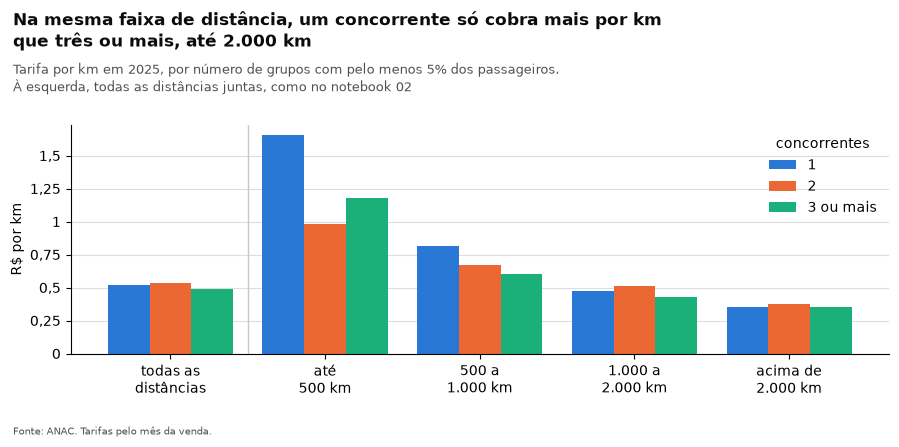

In [6]:
import os
import sys
import urllib.request

if os.path.exists("../visual.py"):
    sys.path.insert(0, "..")
else:  # fora do repositorio (no Colab): o padrao visual vem pela URL bruta
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ivadivad/voos-em-numeros/coleta-2026-10-13/visual.py", "visual.py")
from visual import CATEGORICAS, CINZA, grafico, salvar

ano = com_tarifa[com_tarifa["ano"] == 2025]
por_faixa_2025 = tarifa_km(ano, ["faixa", "classe"]).unstack("classe")
por_faixa_2025.index = por_faixa_2025.index.astype(str)
lado_a_lado = pd.concat([tarifa_km(ano, "classe").to_frame("todas as distâncias").T, por_faixa_2025])
lado_a_lado["1 sobre 3 ou mais (%)"] = (lado_a_lado["1"] / lado_a_lado["3 ou mais"] - 1) * 100
print("tarifa por km em 2025 (R$)")
print(lado_a_lado.round({"1": 3, "2": 3, "3 ou mais": 3, "1 sobre 3 ou mais (%)": 1}).to_string(), "\n")

fig, ax = grafico("Na mesma faixa de distância, um concorrente só cobra mais por km\n"
                  "que três ou mais, até 2.000 km",
                  subtitulo="Tarifa por km em 2025, por número de grupos com pelo menos 5% dos passageiros.\n"
                            "À esquerda, todas as distâncias juntas, como no notebook 02",
                  fonte="Fonte: ANAC. Tarifas pelo mês da venda.")
x = np.arange(len(lado_a_lado))
largura = 0.27
for i, (cor, nome) in enumerate(zip(CATEGORICAS, CLASSES)):
    ax.bar(x + (i - 1) * largura, lado_a_lado[nome], largura, color=cor, label=nome)
ax.axvline(0.5, color=CINZA, linewidth=1)
ax.set_xticks(x, ["todas as\ndistâncias", "até\n500 km", "500 a\n1.000 km", "1.000 a\n2.000 km", "acima de\n2.000 km"])
ax.set_ylabel("R$ por km")
ax.legend(title="concorrentes", frameon=False)
print("gravado em graficos/" + os.path.basename(salvar(fig, "03-antes-e-depois.png")))

**O gráfico da esquerda conta uma meia-verdade.** Com todas as distâncias
juntas, em 2025, um concorrente só cobra 6,9% a mais por km que três ou
mais, e os mercados de dois concorrentes parecem os mais caros. Separando
por faixa, a diferença de um concorrente sobre três ou mais é de 40,6% até
500 km, 35,5% de 500 a 1.000 km e 10,7% de 1.000 a 2.000 km, e só some
acima de 2.000 km (0,9%). Juntar as distâncias escondia a maior parte da
diferença: os mercados de um concorrente são mais longos, e o quilômetro
do mercado longo é mais barato. O da direita é o que estes dados permitem
dizer.

## O que fica

| Comparação | Um concorrente sobre três ou mais |
|---|---|
| Sem controle, 2025 | 6,9% |
| Na mesma faixa, 2025 | de 0,9% (acima de 2.000 km) a 40,6% (até 500 km) |
| Na mesma faixa, 2019 a 2026 | acima nos 8 anos, em toda faixa até 2.000 km |
| Regressão, sem peso | 39,5% |
| Regressão, com peso pelos passageiros | 28,7% |
| Regressão sem os mercado-meses com menos de 100 assentos | 30,9% sem peso e 27,1% com peso |

**A resposta à primeira pergunta, com as ressalvas da seção 4, é sim.** Em
mercados com menos companhias, comparando distâncias parecidas, a tarifa
por quilômetro é mais alta: de 27,1% a 39,5% a mais onde há um grupo só
do que onde há três ou mais, conforme o peso e o corte dos mercados
pequenos, e de 10,1% a 15,6% a mais onde há dois. A diferença vem dos
mercados de até 2.000 km. É associação, não efeito, e vale pras tarifas
registradas, que deixam milhas e descontos restritos de fora.